# Chapter 27: Two players, the GAN game

Checks [chapter 27](../../book/27-two-players.md). The models are exact and tiny: the critic's loss at one input as a
function of one score (sigmoid prediction, cross-entropy), and the payoff `x * y` with simultaneous gradient steps on two
numbers. Everything is NumPy in float64 and deterministic (the only random draws are seeded). Claims 1 to 3 evaluate the chapter's formulas on a grid, so their numbers are "from the formula", not measured; claim 4 runs the game's steps, so its numbers are measured. None of this is a proof: the proofs are in `GanGame.lean`. Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
import matplotlib.pyplot as plt
from common import use_style, save_figure, report as report_check, NEAREST, VERTICAL, BOUND, MODEL, BEFORE

use_style()
SEED = 27
COUNTS = {"could fail and passed": 0, "by construction": 0}


def report(label, passed, detail=""):
    """A check that could fail. It stops the notebook if it does, and is counted if it passes."""
    report_check(label, passed, detail)
    COUNTS["could fail and passed"] += 1


def note_by_construction(text):
    """A line that holds because of how the code is written. It is not evidence and is not counted as a pass."""
    COUNTS["by construction"] += 1
    print("[by construction, cannot fail] " + text)


def squash(score):
    return 1.0 / (1.0 + np.exp(-score))


def get_critic_loss(real_weight, made_weight, score):
    prediction = squash(score)
    return -real_weight * np.log(prediction) - made_weight * np.log(1.0 - prediction)


def get_cross_entropy(label, score):
    prediction = squash(score)
    return -label * np.log(prediction) - (1.0 - label) * np.log(1.0 - prediction)


def take_game_step(learning_rate, state):
    maker, critic = state
    return maker - learning_rate * critic, critic + learning_rate * maker


def take_alternating_step(learning_rate, state):
    maker, critic = state
    maker = maker - learning_rate * critic
    critic = critic + learning_rate * maker
    return maker, critic


def run_game(step_function, learning_rate, state, step_count):
    states = [state]
    for _ in range(step_count):
        state = step_function(learning_rate, state)
        states.append(state)
    return np.array(states)


def get_squared_distance(states):
    return (states ** 2).sum(axis=-1)

## Claim 1: the critic's loss is the total weight times a soft-label cross-entropy (`critic_loss_is_a_log_loss_with_a_soft_label`)

Take 200 random (real weight, made weight, score) triples, weights in `[0.1, 5]`, scores in `[-6, 6]`. The loss
`-real log(p) - made log(1 - p)` must equal `(real + made)` times the cross-entropy with label `real / (real + made)`.
Predicted: they agree to rounding error, about `1e-15` relative. A gap above `1e-10` would count against the claim.

In [2]:
generator = np.random.default_rng(SEED)
real_weights = generator.uniform(0.1, 5.0, 200)
made_weights = generator.uniform(0.1, 5.0, 200)
scores = generator.uniform(-6.0, 6.0, 200)
direct = get_critic_loss(real_weights, made_weights, scores)
factored = (real_weights + made_weights) * get_cross_entropy(real_weights / (real_weights + made_weights), scores)
worst_gap = np.max(np.abs(direct - factored) / direct)
note_by_construction(f"from the formula: critic loss equals total weight times the soft-label cross-entropy (largest relative gap {worst_gap:.1e}): the right side is a rearrangement of the left, -a log p - b log(1 - p) = (a + b) CE(a / (a + b)); not evidence")

[by construction, cannot fail] from the formula: critic loss equals total weight times the soft-label cross-entropy (largest relative gap 1.9e-15): the right side is a rearrangement of the left, -a log p - b log(1 - p) = (a + b) CE(a / (a + b)); not evidence


## Claim 2: the best critic predicts the real share (`best_critic_exists_where_both_are_present`, `best_critic_predicts_the_real_share`, `critic_cannot_tell_when_the_maker_has_won`)

Hand examples of the chapter: weights (3, 1) give 0.75, weights (1, 3) give 0.25, weights (2, 2) give 0.5 with score zero.
For these and the 200 random weight pairs above, search a fine grid of scores in `[-12, 12]` (step 0.001). Predicted: the
grid minimum has a prediction within `1e-3` of the real share, and no grid score has a loss below the loss at the share's
own score by more than rounding. A grid minimum further from the share than `1e-3` would count against the claim.

In [3]:
SCORE_GRID = np.arange(-12.0, 12.0 + 5e-4, 1e-3)


def find_best_prediction(real_weight, made_weight):
    losses = get_critic_loss(real_weight, made_weight, SCORE_GRID)
    best = int(np.argmin(losses))
    return squash(SCORE_GRID[best]), SCORE_GRID[best], losses[best]


hand_cases = [(3.0, 1.0, 0.75), (1.0, 3.0, 0.25), (2.0, 2.0, 0.5)]
for real_weight, made_weight, expected in hand_cases:
    prediction, score, _ = find_best_prediction(real_weight, made_weight)
    print(f"weights ({real_weight:g}, {made_weight:g}): best prediction {prediction:.4f}, share {expected}")
    report(f"from the formula: hand example ({real_weight:g}, {made_weight:g}) predicts {expected}", abs(prediction - expected) < 1e-3)
_, equal_score, _ = find_best_prediction(2.0, 2.0)
report("from the formula: equal weights: the best score is zero", abs(equal_score) < 1e-3, f"best score {equal_score:.4f}")

worst_prediction_gap = 0.0
worst_loss_excess = 0.0
for real_weight, made_weight in zip(real_weights, made_weights):
    share = real_weight / (real_weight + made_weight)
    prediction, _, best_loss = find_best_prediction(real_weight, made_weight)
    share_score = np.log(share / (1.0 - share))
    share_loss = get_critic_loss(real_weight, made_weight, share_score)
    worst_prediction_gap = max(worst_prediction_gap, abs(prediction - share))
    worst_loss_excess = max(worst_loss_excess, share_loss - best_loss)
report("from the formula: best grid prediction is the real share, for 200 weight pairs", worst_prediction_gap < 1e-3,
       f"largest gap {worst_prediction_gap:.1e}")
note_by_construction(f"no grid score beats the share's score (largest excess {worst_loss_excess:.1e}): the excess starts at 0.0 and the share's score is the true minimum, so it can only print 0; not evidence (the grid-minimum check above is the real one)")
print(f"[from the formula] the largest gap {worst_prediction_gap:.1e} between the grid prediction and the real share comes from the score step 1e-3: it is about p (1 - p) times half a step, at most 0.25 * 5e-4 = 1.25e-4")

weights (3, 1): best prediction 0.7501, share 0.75
[PASS] from the formula: hand example (3, 1) predicts 0.75
weights (1, 3): best prediction 0.2499, share 0.25
[PASS] from the formula: hand example (1, 3) predicts 0.25
weights (2, 2): best prediction 0.5000, share 0.5
[PASS] from the formula: hand example (2, 2) predicts 0.5
[PASS] from the formula: equal weights: the best score is zero  (best score -0.0000)
[PASS] from the formula: best grid prediction is the real share, for 200 weight pairs  (largest gap 1.2e-04)
[by construction, cannot fail] no grid score beats the share's score (largest excess 0.0e+00): the excess starts at 0.0 and the share's score is the true minimum, so it can only print 0; not evidence (the grid-minimum check above is the real one)
[from the formula] the largest gap 1.2e-04 between the grid prediction and the real share comes from the score step 1e-3: it is about p (1 - p) times half a step, at most 0.25 * 5e-4 = 1.25e-4


## Claim 3: with no made data the loss goes down for ever (`no_score_is_best_where_made_data_is_absent`)

Real weight 1, made weight 0, scores `-12` to `12` in steps of 0.001. Predicted: every step of the score lowers the loss
(strictly), the lowest loss is at the right edge of the grid, and the prediction there is below 1 but within `1e-5` of it.
The control is the same real weight with a small made weight, 0.01: then the loss is not monotone and its minimum is inside
the grid, at the share's score `log(100)` (about 4.6). If the control were also monotone, the claim would say nothing about
the missing made data.

[PASS] from the formula: no made data: loss strictly decreases at every score step  (largest change -6.15e-09)
[PASS] from the formula: no made data: the lowest loss is at the right edge of the grid  (best score 12.0, loss 6.14e-06)
[by construction, cannot fail] the prediction at the grid edge is below 1 by 6.14e-06 = exp(-12) = 6.14e-06: an effect of the grid edge being 12, not a claim about the loss; not evidence
[PASS] from the formula: control: with made weight 0.01 the loss has an inner minimum at log(100)  (best score 4.605, log(100) = 4.605)


wrote book/figures/27-critic-loss-against-score.png


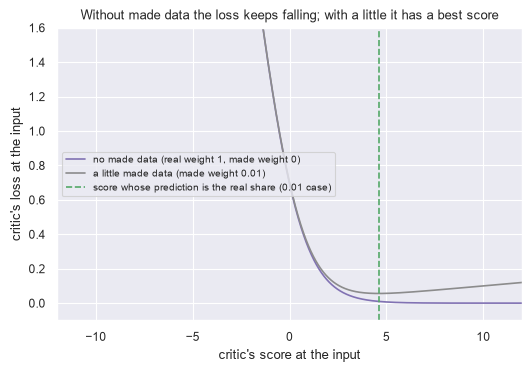

In [4]:
loss_without_made = get_critic_loss(1.0, 0.0, SCORE_GRID)
loss_steps = np.diff(loss_without_made)
report("from the formula: no made data: loss strictly decreases at every score step", bool(np.all(loss_steps < 0)),
       f"largest change {loss_steps.max():.2e}")
report("from the formula: no made data: the lowest loss is at the right edge of the grid",
       int(np.argmin(loss_without_made)) == len(SCORE_GRID) - 1,
       f"best score {SCORE_GRID[np.argmin(loss_without_made)]:.1f}, loss {loss_without_made.min():.2e}")
edge_prediction = float(squash(SCORE_GRID[-1]))
note_by_construction(f"the prediction at the grid edge is below 1 by {1.0 - edge_prediction:.2e} = exp(-12) = {np.exp(-12.0):.2e}: an effect of the grid edge being 12, not a claim about the loss; not evidence")

loss_with_little_made = get_critic_loss(1.0, 0.01, SCORE_GRID)
best_control_score = SCORE_GRID[np.argmin(loss_with_little_made)]
report("from the formula: control: with made weight 0.01 the loss has an inner minimum at log(100)",
       abs(best_control_score - np.log(100.0)) < 2e-3 and 0 < np.argmin(loss_with_little_made) < len(SCORE_GRID) - 1,
       f"best score {best_control_score:.3f}, log(100) = {np.log(100.0):.3f}")

figure, axis = plt.subplots(figsize=(6.0, 3.8))
axis.plot(SCORE_GRID, loss_without_made, color=MODEL, label="no made data (real weight 1, made weight 0)")
axis.plot(SCORE_GRID, loss_with_little_made, color=BEFORE, label="a little made data (made weight 0.01)")
axis.axvline(np.log(100.0), color=BOUND, linestyle="--", label="score whose prediction is the real share (0.01 case)")
axis.set_ylim(-0.1, 1.6)
axis.set_xlim(-12, 12)
axis.set_xlabel("critic's score at the input")
axis.set_ylabel("critic's loss at the input")
axis.set_title("Without made data the loss keeps falling; with a little it has a best score")
axis.legend(loc="center left", fontsize=7)
save_figure(figure, "27-critic-loss-against-score")
plt.show()

## Claim 4: the players spiral outward (`one_game_step_moves_outward`, `players_spiral_outward`, `every_game_step_moves_further_from_rest`)

Start at `(1, 0)` with learning rate 0.1. The chapter's hand path is `(1, 0)`, `(1, 0.1)`, `(0.99, 0.2)`. Predicted: the
squared distance from rest `x^2 + y^2` equals `1.01` to the power of the step count, up to rounding (relative `1e-12` at 300
steps). Then 200 random starts, learning rates in `[0.01, 0.5]`, and step counts up to 100: the measured squared distance
must equal `(1 + learning_rate^2)^n` times the starting one, and every step must increase it. For the chapter's question 2:
rate 0.2 gives 1.04 per step, and `1.04^25` is about 2.67. A relative gap above `1e-9` anywhere, or one step that does not
increase the distance, counts against the claim.

The control is alternating steps (the maker moves first, then the critic sees the new maker), where "both step at the same
time" is broken. The chapter does not analyse that case; here we only measure whether the squared distance still grows by
`1 + learning_rate^2` per step. Predicted if the factor were universal: alternating would end near the simultaneous
value. A threshold was first set at 1 percent of the proved value, a guess that the measured peak of about 1.05 missed; it was then widened to 10 percent. Because that threshold was set after seeing a first result, the control is now **reported, not tested**: the cell prints the range of the squared distance for alternating steps. It also tries two more learning rates (0.05 and 0.3) and two more starts (seeded) and prints all nine cases.

[PASS] hand path: (1, 0), (1, 0.1), (0.99, 0.2)  ([[1.0, 0.0], [1.0, 0.1], [0.99, 0.2]])
[by construction, cannot fail] squared distance is 1.01 to the power of the step count, over 300 steps (exact iteration of the rule, largest relative gap 3.4e-15; first three [1.0, 1.01, 1.0201]): the closed form is an identity of the update; not evidence
[by construction, cannot fail] random starts, rates and counts: squared distance equals (1 + rate^2)^n times the start (exact iteration of the rule, largest relative gap 9.7e-15); not evidence
[by construction, cannot fail] every step off rest moves further from rest (0 steps did not grow): follows from the closed form, since 1 + rate^2 > 1; not evidence
[by construction, cannot fail] check yourself: rate 0.2 gives 1.04 per step and about 2.67 over 25 steps (exact iteration of the rule: one step 1.0400, 25 steps 2.6658); not evidence
alternating: squared distance ranges from 0.9524 to 1.0526
[report, not a test] control: alternating steps from (1,

wrote book/figures/27-spiral-outward.png


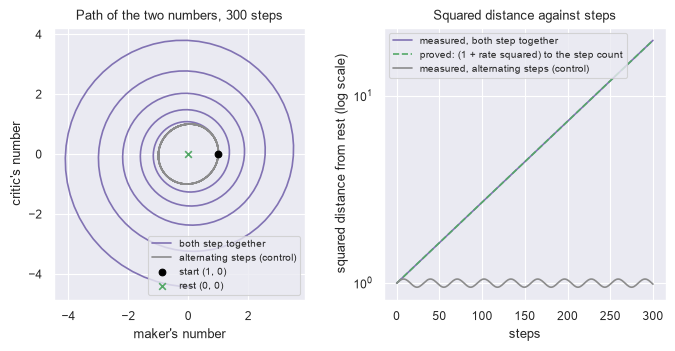

In [5]:
LEARNING_RATE = 0.1
STEP_COUNT = 300
simultaneous = run_game(take_game_step, LEARNING_RATE, (1.0, 0.0), STEP_COUNT)
report("hand path: (1, 0), (1, 0.1), (0.99, 0.2)",
       np.allclose(simultaneous[:3], [[1.0, 0.0], [1.0, 0.1], [0.99, 0.2]]), str(simultaneous[:3].tolist()))
squared = get_squared_distance(simultaneous)
proved_squared = (1.0 + LEARNING_RATE ** 2) ** np.arange(STEP_COUNT + 1)
spiral_gap = np.max(np.abs(squared - proved_squared) / proved_squared)
note_by_construction(f"squared distance is 1.01 to the power of the step count, over 300 steps (exact iteration of the rule, largest relative gap {spiral_gap:.1e}; first three {squared[:3].round(4).tolist()}): the closed form is an identity of the update; not evidence")

generator = np.random.default_rng(SEED + 1)
worst_random_gap = 0.0
steps_not_growing = 0
for _ in range(200):
    rate = generator.uniform(0.01, 0.5)
    start = tuple(generator.uniform(-2, 2, 2))
    count = int(generator.integers(1, 101))
    path = run_game(take_game_step, rate, start, count)
    squared_path = get_squared_distance(path)
    proved = (1.0 + rate ** 2) ** count * squared_path[0]
    worst_random_gap = max(worst_random_gap, abs(squared_path[-1] - proved) / proved)
    steps_not_growing += int(np.sum(np.diff(squared_path) <= 0))
note_by_construction(f"random starts, rates and counts: squared distance equals (1 + rate^2)^n times the start (exact iteration of the rule, largest relative gap {worst_random_gap:.1e}); not evidence")
note_by_construction(f"every step off rest moves further from rest ({steps_not_growing} steps did not grow): follows from the closed form, since 1 + rate^2 > 1; not evidence")

check_path = get_squared_distance(run_game(take_game_step, 0.2, (1.0, 0.0), 25))
note_by_construction(f"check yourself: rate 0.2 gives 1.04 per step and about 2.67 over 25 steps (exact iteration of the rule: one step {check_path[1]:.4f}, 25 steps {check_path[25]:.4f}); not evidence")

alternating = run_game(take_alternating_step, LEARNING_RATE, (1.0, 0.0), STEP_COUNT)
alternating_squared = get_squared_distance(alternating)
alternating_largest = alternating_squared.max()
print(f"alternating: squared distance ranges from {alternating_squared.min():.4f} to {alternating_largest:.4f}")
print(f"[report, not a test] control: alternating steps from (1, 0) at rate {LEARNING_RATE}: largest squared distance {alternating_largest:.4f}, smallest {alternating_squared.min():.4f}; the simultaneous value at step {STEP_COUNT} is {proved_squared[-1]:.2f}. The threshold for this control (10 percent of the simultaneous value) was set after a first result missed 1 percent, so this line describes the run and is not a test")

# More rates and starts for the alternating control (own seeded generator).
extra_generator = np.random.default_rng(SEED + 5)
extra_starts = [(1.0, 0.0)] + [tuple(extra_generator.uniform(-2.0, 2.0, 2)) for _ in range(2)]
print("alternating steps, 300 steps: squared distance divided by the starting one (smallest, largest), against the simultaneous factor (1 + rate^2)^300")
for rate in (0.05, 0.1, 0.3):
    for start in extra_starts:
        alternating_path = get_squared_distance(run_game(take_alternating_step, rate, start, STEP_COUNT))
        relative = alternating_path / alternating_path[0]
        print(f"  rate {rate}, start ({start[0]:.3f}, {start[1]:.3f}): smallest {relative.min():.4f}, largest {relative.max():.4f}; simultaneous factor {(1.0 + rate ** 2) ** STEP_COUNT:.2f}")

figure, (path_axis, distance_axis) = plt.subplots(1, 2, figsize=(7.0, 3.6))
path_axis.plot(simultaneous[:, 0], simultaneous[:, 1], color=MODEL, label="both step together")
path_axis.plot(alternating[:, 0], alternating[:, 1], color=BEFORE, label="alternating steps (control)")
path_axis.scatter([1.0], [0.0], color="black", zorder=3, label="start (1, 0)")
path_axis.scatter([0.0], [0.0], color=BOUND, marker="x", zorder=3, label="rest (0, 0)")
path_axis.set_aspect("equal")
path_axis.set_xlabel("maker's number")
path_axis.set_ylabel("critic's number")
path_axis.set_title("Path of the two numbers, 300 steps")
path_axis.legend(fontsize=7)
steps = np.arange(STEP_COUNT + 1)
distance_axis.plot(steps, squared, color=MODEL, label="measured, both step together")
distance_axis.plot(steps, proved_squared, color=BOUND, linestyle="--", label="proved: (1 + rate squared) to the step count")
distance_axis.plot(steps, alternating_squared, color=BEFORE, label="measured, alternating steps (control)")
distance_axis.set_yscale("log")
distance_axis.set_xlabel("steps")
distance_axis.set_ylabel("squared distance from rest (log scale)")
distance_axis.set_title("Squared distance against steps")
distance_axis.legend(fontsize=7)
figure.tight_layout()
save_figure(figure, "27-spiral-outward")
plt.show()

In [6]:
print(f"measured: squared distance after {STEP_COUNT} steps at rate {LEARNING_RATE} is {squared[-1]:.4f} "
      f"against the proved {proved_squared[-1]:.4f}; alternating peaks at {alternating_largest:.4f}")

measured: squared distance after 300 steps at rate 0.1 is 19.7885 against the proved 19.7885; alternating peaks at 1.0526


In [7]:
print(f"checks that could fail and passed: {COUNTS['could fail and passed']}; printed as by construction, not counted: {COUNTS['by construction']}")

checks that could fail and passed: 9; printed as by construction, not counted: 7
